#####This project focuses on analyzing hotel booking data from City Hotels and Resort Hotels to understand booking patterns, customer behavior, cancellations, seasonal demand, and revenue-related indicators.

The dataset contains information about booking details, arrival dates, length of stay, number of guests, customer types, market segments, distribution channels, room preferences, cancellation status, and Average Daily Rate (ADR).

Python is used to clean, transform, and prepare the dataset for further analysis. The data cleaning process involves identifying and handling missing values, removing duplicate records, correcting data types, standardizing inconsistent values, identifying invalid entries, and creating relevant features.

The cleaned dataset will provide a reliable foundation for the subsequent stages of the project.

In [ ]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #A67883;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color: 	#28282B; margin: 0;">
2. Objective
</h2>
</div>
"""))

#####To analyze hotel booking patterns, identify factors influencing cancellations, understand customer segments and booking channels, examine seasonal demand, and evaluate booking revenue indicators to support better hotel business and revenue management decisions.


In [ ]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #A67883;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color:	#28282B; margin: 0;">
3. Dataset Introduction
</h2>
</div>
"""))



##### Dataset Description:

- **Dataset Name:** Hotel Booking Demand Dataset
- **File Name:** `hotel_bookings.csv`
- **Number of Records:** 119,390 rows
- **Number of Columns:** 32
- **Hotel Types:** City Hotel and Resort Hotel
- **Data Period:** 2015–2017
- **File Format:** CSV

---


##### Dataset Overview:

The dataset contains hotel booking records from two types of hotels: City Hotels and Resort Hotels. It includes information about booking dates, guest details, length of stay, booking channels, customer segments, room assignments, cancellations, and pricing.

Each row represents a booking record. The dataset provides an opportunity to examine booking trends, cancellation patterns, customer preferences, seasonal demand, and revenue-related indicators.

The dataset will be examined and preprocessed before proceeding to further analysis.

In [ ]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #A67883;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color: 	#28282B; margin: 0;">
4. Dataset Column Description (Data Dictionary)
</h2>
</div>
"""))



#####The dataset consists of 32 columns, each representing a specific aspect of hotel bookings. The columns are grouped below based on their purpose.

**A. Hotel and Booking Information**

1. hotel – Identifies the type of hotel, either City Hotel or Resort Hotel.
2. is_canceled – Indicates whether the booking was canceled (1) or not canceled (0).
3. lead_time – Represents the number of days between the booking date and the arrival date.
4. arrival_date_year – Specifies the year of arrival.
5. arrival_date_month – Specifies the month of arrival.
6. arrival_date_week_number – Indicates the week number of the arrival date.
7. arrival_date_day_of_month – Specifies the day of the month of arrival.

**B. Stay and Guest Information**

8. stays_in_weekend_nights – Number of weekend nights (Saturday and Sunday) included in the booking.
9. stays_in_week_nights – Number of weekday nights included in the booking.
10. adults – Number of adults included in the booking.
11. children – Number of children included in the booking.
12. babies – Number of babies included in the booking.

**C. Customer and Booking Channel Information**

13. meal – Type of meal selected as part of the booking.
14. country – Country of origin of the guest.
15. market_segment – Market segment associated with the booking.
16. distribution_channel – Channel through which the booking was made.
17. is_repeated_guest – Indicates whether the guest has stayed at the hotel before (1) or is a first-time guest (0).
18. customer_type – Category of customer associated with the booking.

**D. Previous Booking History**

19. previous_cancellations – Number of previous bookings canceled by the guest.
20. previous_bookings_not_canceled – Number of previous bookings that were not canceled by the guest.

**E. Room and Reservation Details**

21. reserved_room_type – Room type originally reserved by the guest.
22. assigned_room_type – Room type actually assigned to the guest.
23. booking_changes – Number of changes made to the booking after the initial reservation.
24. deposit_type – Type of deposit required for the booking.
25. agent – Identification number of the travel agency responsible for the booking, if applicable.
26. company – Identification number of the company responsible for the booking, if applicable.
27. days_in_waiting_list – Number of days the booking remained on the waiting list before confirmation.

**F. Pricing and Guest Requirements**

28. adr – Average Daily Rate, representing the average revenue per occupied room per day.
29. required_car_parking_spaces – Number of car parking spaces requested by the guest.
30. total_of_special_requests – Total number of special requests made by the guest.

**G. Reservation Status Information**

31. reservation_status – Final status of the reservation, such as Canceled, Check-Out, or No-Show.
32. reservation_status_date – Date on which the reservation status was last updated.

In [4]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #D87093;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color: 	#28282B; margin: 0;">
Data Cleaning & Pre-processing
</h2>
</div>
"""))

**1. Import libraries and load the dataset**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_raw = pd.read_csv("hotel_bookings.csv")
df = df_raw.copy()

print("Rows and columns:", df.shape)
display(df.head())
df.info()

Rows and columns: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

#####*pandas is used for tabular cleaning and analysis; NumPy supports numerical operations; Matplotlib/Seaborn support visual checks.*

####**2. Initial data audit**

In [ ]:
print("Shape:", df.shape)
print("\\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\\nExact duplicate rows:", df.duplicated().sum())
display(df.describe(include="all").T)
for col in df.select_dtypes(include="object").columns:
    print(f"\\n{col}:")
    print(df[col].value_counts(dropna=False).head(20))

Shape: (119390, 32)
\nData types:


,dtype
hotel,object
is_canceled,int64
lead_time,int64
arrival_date_year,int64
arrival_date_month,object
arrival_date_week_number,int64
arrival_date_day_of_month,int64
stays_in_weekend_nights,int64
stays_in_week_nights,int64
adults,int64


\nMissing values:


,missing_count
company,112593
agent,16340
country,488
children,4
arrival_date_month,0
arrival_date_week_number,0
hotel,0
is_canceled,0
stays_in_weekend_nights,0
arrival_date_day_of_month,0


\nExact duplicate rows: 31994


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
hotel,119390,2,City Hotel,79330,NaN,NaN,NaN,NaN,NaN,NaN,NaN
is_canceled,119390.0,NaN,NaN,NaN,0.370416,0.482918,0.0,0.0,0.0,1.0,1.0
lead_time,119390.0,NaN,NaN,NaN,104.011416,106.863097,0.0,18.0,69.0,160.0,737.0
arrival_date_year,119390.0,NaN,NaN,NaN,2016.156554,0.707476,2015.0,2016.0,2016.0,2017.0,2017.0
arrival_date_month,119390,12,August,13877,NaN,NaN,NaN,NaN,NaN,NaN,NaN
arrival_date_week_number,119390.0,NaN,NaN,NaN,27.165173,13.605138,1.0,16.0,28.0,38.0,53.0
arrival_date_day_of_month,119390.0,NaN,NaN,NaN,15.798241,8.780829,1.0,8.0,16.0,23.0,31.0
stays_in_weekend_nights,119390.0,NaN,NaN,NaN,0.927599,0.998613,0.0,0.0,1.0,2.0,19.0
stays_in_week_nights,119390.0,NaN,NaN,NaN,2.500302,1.908286,0.0,1.0,2.0,3.0,50.0
adults,119390.0,NaN,NaN,NaN,1.856403,0.579261,0.0,2.0,2.0,2.0,55.0


\nhotel:
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64
\narrival_date_month:
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64
\nmeal:
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64
\ncountry:
country
PRT    48590
GBR    12129
FRA    10415
ESP     8568
DEU     7287
ITA     3766
IRL     3375
BEL     2342
BRA     2224
NLD     2104
USA     2097
CHE     1730
CN      1279
AUT     1263
SWE     1024
CHN      999
POL      919
ISR      669
RUS      632
NOR      607
Name: count, dtype: int64
\nmarket_segment:
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation  

#####*Before changing data, establish the baseline: column names, data types, missing values, duplicates, category values, and numerical ranges. This lets us justify each cleaning decision and compare before/after.*

In [ ]:
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": df.isnull().mean() * 100
})

display(missing_summary[missing_summary["Missing_Count"] > 0])

,Missing_Count,Missing_Percentage
children,4,0.003350
country,488,0.408744
agent,16340,13.686238
company,112593,94.306893


#####*The output identifies columns containing missing values and their proportion in the dataset.*

In [ ]:
unique_summary = pd.DataFrame({
    "Unique_Count": df.nunique(dropna=False)
})

display(unique_summary)

,Unique_Count
hotel,2
is_canceled,2
lead_time,479
arrival_date_year,3
arrival_date_month,12
arrival_date_week_number,53
arrival_date_day_of_month,31
stays_in_weekend_nights,17
stays_in_week_nights,35
adults,14


#####*Columns with fewer distinct values may represent categories, while columns with many distinct values may contain IDs or continuous measurements.*

#####**3. Standardize column names**

In [ ]:
df.columns = (df.columns.str.strip().str.lower().str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print(df.columns.tolist())

['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']


#####*Method: lowercase, trim spaces, replace spaces with underscores.*
*Reason: consistent snake_case names reduce typing mistakes and make columns easier to use in Python. No information is removed*

In [ ]:

object_columns = df.select_dtypes(include="object").columns

for col in object_columns:
    df[col] = df[col].map(
        lambda x: x.strip() if isinstance(x, str) else x
    )


In [ ]:
for col in ["meal", "market_segment", "distribution_channel",
             "customer_type", "reservation_status"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))


meal
meal
BB           92310
HB           14463
SC           10650
Undefined     1169
FB             798
Name: count, dtype: int64

market_segment
market_segment
Online TA        56477
Offline TA/TO    24219
Groups           19811
Direct           12606
Corporate         5295
Complementary      743
Aviation           237
Undefined            2
Name: count, dtype: int64

distribution_channel
distribution_channel
TA/TO        97870
Direct       14645
Corporate     6677
GDS            193
Undefined        5
Name: count, dtype: int64

customer_type
customer_type
Transient          89613
Transient-Party    25124
Contract            4076
Group                577
Name: count, dtype: int64

reservation_status
reservation_status
Check-Out    75166
Canceled     43017
No-Show       1207
Name: count, dtype: int64


#####*Text values are cleaned of surrounding spaces. Category counts are reviewed to identify remaining inconsistencies.*

#####**4. Remove duplicate records**

In [ ]:
duplicate_count = df.duplicated().sum()
print("Exact duplicates before:", duplicate_count)
df = df.drop_duplicates().copy()
print("Rows after exact deduplication:", len(df))

Exact duplicates before: 31994
Rows after exact deduplication: 87396


#####*drop_duplicates() keeps the first copy of an identical row.*

*Only exact duplicate rows were removed. Since the dataset does not contain a unique booking ID, identical records cannot always be confirmed as accidental duplicates. This is a limitation to consider when interpreting the results.*

#####**5. Correct data types and create the arrival date**

In [ ]:
dtype_audit = pd.DataFrame({
    "Column": df.columns,
    "Current_Dtype": df.dtypes.astype(str).values
})

display(dtype_audit)

,Column,Current_Dtype
0,hotel,object
1,is_canceled,int64
2,lead_time,int64
3,arrival_date_year,int64
4,arrival_date_month,object
5,arrival_date_week_number,int64
6,arrival_date_day_of_month,int64
7,stays_in_weekend_nights,int64
8,stays_in_week_nights,int64
9,adults,int64


In [ ]:
df["reservation_status_date"] = pd.to_datetime(df["reservation_status_date"], errors="coerce")

month_map = {month: number for number, month in enumerate(
    ["January","February","March","April","May","June","July","August","September","October","November","December"], 1)}
df["arrival_month_num"] = df["arrival_date_month"].map(month_map)

df["arrival_date"] = pd.to_datetime(
    dict(year=df["arrival_date_year"], month=df["arrival_month_num"],
         day=df["arrival_date_day_of_month"]), errors="coerce")

print(df[["arrival_date_year","arrival_date_month","arrival_date_day_of_month","arrival_date"]].head())
print("Invalid arrival dates:", df["arrival_date"].isna().sum())
print(df[["reservation_status_date","arrival_date"]].dtypes)

   arrival_date_year arrival_date_month  arrival_date_day_of_month  \
0               2015               July                          1   
1               2015               July                          1   
2               2015               July                          1   
3               2015               July                          1   
4               2015               July                          1   

  arrival_date  
0   2015-07-01  
1   2015-07-01  
2   2015-07-01  
3   2015-07-01  
4   2015-07-01  
Invalid arrival dates: 0
reservation_status_date    datetime64[ns]
arrival_date               datetime64[ns]
dtype: object


#####*Method: parse reservation_status_date as datetime; map month names to month numbers; construct arrival_date from year/month/day.*
*Reason: date types enable chronological sorting, time-based analysis, and date features. The source provides arrival year, month name, and day separately, so combine them into one real date.*

In [ ]:
dtype_audit_after = pd.DataFrame({
    "Column": df.columns,
    "Updated_Dtype": df.dtypes.astype(str).values
})

display(dtype_audit_after)

,Column,Updated_Dtype
0,hotel,object
1,is_canceled,int64
2,lead_time,int64
3,arrival_date_year,int64
4,arrival_date_month,object
5,arrival_date_week_number,int64
6,arrival_date_day_of_month,int64
7,stays_in_weekend_nights,int64
8,stays_in_week_nights,int64
9,adults,int64


#####*Date columns should be datetime, numerical columns should be numeric, and categorical columns should retain appropriate categorical or object types.*

In [ ]:
arrival_date_invalid = df["arrival_date"].isna().sum()

print("Invalid arrival dates:", arrival_date_invalid)
print("Arrival date range:",
      df["arrival_date"].min(),
      "to",
      df["arrival_date"].max())

Invalid arrival dates: 0
Arrival date range: 2015-07-01 00:00:00 to 2017-08-31 00:00:00


#####*Invalid arrival dates should be investigated. Valid dates should fall within the expected dataset period.*

*Assessment of Column Splitting and Merging:
The arrival year, month, and day components are combined into a single arrival date to simplify date-based operations.*

*No other columns require splitting or merging at this stage. The original arrival date components are retained to preserve the original dataset information.*

#####**6. Missing values and placeholder categories**

In [ ]:
# Preserve indicators before filling
df["agent_was_missing"] = df["agent"].isna().astype("int8")
df["company_was_missing"] = df["company"].isna().astype("int8")

df["children"] = df["children"].fillna(0)
df["country"] = df["country"].fillna("Unknown")
df["agent"] = df["agent"].fillna(0)
df["company"] = df["company"].fillna(0)

for col in ["meal","market_segment","distribution_channel"]:
    df[col] = df[col].replace("Undefined", "Unknown")

print("Missing values after handling:")
display(df.isna().sum().sort_values(ascending=False).head(15))

Missing values after handling:


,0
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0


#####*First inspect missingness and the meaning of each field. Do not blindly drop rows or fill every column with a mean.*

- children: only 4 missing; treat as 0 children (small count and count variable), while recording the decision.
- country: missing country is unknown; fill with "Unknown" (not a guessed country).
- agent and company: missing generally means no agent/company was recorded. Use 0 as a documented “no agent/company” code, and retain the original missingness indicators for transparency.
- Undefined in categorical fields is a placeholder, not a valid business category; convert to "Unknown".
- Do not impute target is_canceled or other key outcomes; this dataset has no missing target values.

#####**7. Validate values and handle invalid records**

In [ ]:
df["total_guests"] = df["adults"] + df["children"] + df["babies"]
invalid_zero_guest = df["total_guests"].eq(0)
invalid_negative_adr = df["adr"].lt(0)
invalid_negative_counts = (
    df[["lead_time","stays_in_weekend_nights","stays_in_week_nights","adults","children","babies",
        "previous_cancellations","previous_bookings_not_canceled","booking_changes",
        "days_in_waiting_list","required_car_parking_spaces","total_of_special_requests"]].lt(0).any(axis=1)
)
print("Zero-guest records:", invalid_zero_guest.sum())
print("Negative ADR records:", invalid_negative_adr.sum())
print("Negative count/duration records:", invalid_negative_counts.sum())

df = df.loc[~(invalid_zero_guest | invalid_negative_adr | invalid_negative_counts)].copy()
print("Shape after invalid-record removal:", df.shape)

Zero-guest records: 166
Negative ADR records: 1
Negative count/duration records: 0
Shape after invalid-record removal: (87229, 37)


#####*Rules: counts/durations should not be negative; guest count should be positive; ADR (average daily rate) should not be negative.*
- Remove records with zero total guests: they cannot represent an occupied guest booking and are unsuitable for guest/booking analysis.
- Remove negative ADR (invalid rate).
- Do not delete high but non-negative ADR or unusually large guest counts automatically: they may be genuine group bookings or special rates. Flag them for review instead.
- Zero ADR can be legitimate (complimentary bookings), so retain it.

In [ ]:
binary_columns = ["is_canceled", "is_repeated_guest"]

for col in binary_columns:
    print(f"{col}:")
    print(df[col].value_counts(dropna=False))
    print("Unexpected values:",
          df.loc[~df[col].isin([0, 1]), col].unique())

is_canceled:
is_canceled
0    63220
1    24009
Name: count, dtype: int64
Unexpected values: []
is_repeated_guest:
is_repeated_guest
0    83866
1     3363
Name: count, dtype: int64
Unexpected values: []


#####*Only 0 and 1 are valid values for these columns. Any unexpected values must be investigated before correction.*

#####*The original columns are reviewed to determine whether any are redundant or irrelevant to the project objective. All original columns are retained because they may support booking analysis, cancellation analysis, customer segmentation, and revenue-related analysis in later stages.*

*No original columns are removed at this stage.*

#####**8. Outlier detection**

In [ ]:

def iqr_bounds(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

outlier_columns = [
    "adr",
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights"
]

outlier_results = []

for col in outlier_columns:
    lower, upper = iqr_bounds(df[col])

    flag = (df[col] < lower) | (df[col] > upper)

    df[f"{col}_outlier_flag"] = flag.astype("int8")

    outlier_results.append({
        "Column": col,
        "Lower_Bound": lower,
        "Upper_Bound": upper,
        "Outlier_Count": flag.sum(),
        "Outlier_Percentage": flag.mean() * 100
    })

outlier_summary = pd.DataFrame(outlier_results)
display(outlier_summary)


,Column,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,adr,-20.525,226.875,2508,2.875191
1,lead_time,-160.000,296.000,2394,2.744500
2,stays_in_weekend_nights,-3.000,5.000,213,0.244185
3,stays_in_week_nights,-3.500,8.500,1514,1.735661


#####*Method: The IQR rule is applied to ADR, lead time, weekend nights, and weekday nights. Total guests are excluded because Q1 and Q3 are identical, making the IQR method unsuitable for this column.*
*Reason: The IQR method identifies potentially unusual values. Since extreme prices and long stays may be genuine hotel bookings, outliers are flagged for review rather than automatically deleted.*

#####**9. Feature engineering**

In [ ]:
df["total_nights"] = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]
df["arrival_quarter"] = df["arrival_date"].dt.quarter
df["arrival_day_of_week"] = df["arrival_date"].dt.day_name()
df["is_weekend_arrival"] = df["arrival_date"].dt.dayofweek.isin([5,6]).astype("int8")
df["has_children_or_babies"] = ((df["children"] + df["babies"]) > 0).astype("int8")
df["room_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype("int8")
df["revenue_proxy"] = df["adr"] * df["total_nights"]

# ADR is a daily rate; revenue_proxy is an approximation and not a verified final bill.
display(df[["total_nights","arrival_quarter","arrival_day_of_week","is_weekend_arrival",
            "has_children_or_babies","room_changed","revenue_proxy"]].head())

,total_nights,arrival_quarter,arrival_day_of_week,is_weekend_arrival,has_children_or_babies,room_changed,revenue_proxy
0,0,3,Wednesday,0,0,0,0.0
1,0,3,Wednesday,0,0,0,0.0
2,1,3,Wednesday,0,0,1,75.0
3,1,3,Wednesday,0,0,0,75.0
4,2,3,Wednesday,0,0,0,196.0


#####*derived features answer business questions more directly than raw fields.*

#####**10. Check consistency and inspect business logic**

In [ ]:
print("Bookings with 0 nights:", (df["total_nights"] == 0).sum())
print("Room type changed:", df["room_changed"].value_counts())
print("Reservation status vs cancellation flag:")
display(pd.crosstab(df["is_canceled"], df["reservation_status"], margins=True))
print("Arrival dates:", df["arrival_date"].min(), "to", df["arrival_date"].max())
print("ADR range:", df["adr"].min(), "to", df["adr"].max())
print("Final missing values:", df.isna().sum().sum())

Bookings with 0 nights: 591
Room type changed: room_changed
0    74240
1    12989
Name: count, dtype: int64
Reservation status vs cancellation flag:


reservation_status,Canceled,Check-Out,No-Show,All
is_canceled,,,,
0,0,63220,0,63220
1,22996,0,1013,24009
All,22996,63220,1013,87229


Arrival dates: 2015-07-01 00:00:00 to 2017-08-31 00:00:00
ADR range: 0.0 to 5400.0
Final missing values: 0


#####*cleaning should include logical checks, not just null handling.*

#####**11. GroupBy**

In [ ]:
# Monthly booking volume and cancellation rate
monthly = (df.groupby(["arrival_date_year","arrival_month_num"], as_index=False)
             .agg(bookings=("is_canceled","size"),
                  cancellations=("is_canceled","sum"),
                  avg_adr=("adr","mean"),
                  avg_lead_time=("lead_time","mean")))
monthly["cancellation_rate"] = monthly["cancellations"] / monthly["bookings"]
display(monthly.head(12))

# Market-segment-level cancellation rate
market_segment_summary = (df.groupby("market_segment", as_index=False)
                     .agg(bookings=("is_canceled","size"),
                          cancellation_rate=("is_canceled","mean"),
                          avg_adr=("adr","mean")))
market_segment_summary["cancellation_rate"] *= 100
display(market_segment_summary.sort_values("bookings", ascending=False))

# Hotel-wise overview
display(df.groupby("hotel").agg(bookings=("is_canceled","size"),
                                cancellation_rate=("is_canceled","mean"),
                                avg_adr=("adr","mean"),
                                avg_nights=("total_nights","mean")))

,arrival_date_year,arrival_month_num,bookings,cancellations,avg_adr,avg_lead_time,cancellation_rate
0,2015,7,1672,512,112.533828,79.751196,0.306220
1,2015,8,2447,571,123.295971,58.968533,0.233347
2,2015,9,2834,565,100.054404,74.497883,0.199365
3,2015,10,2694,440,79.101244,58.093170,0.163326
4,2015,11,1662,243,59.339651,35.450662,0.146209
5,2015,12,1975,372,71.793853,38.735190,0.188354
6,2016,1,1849,301,62.698459,22.248242,0.162791
7,2016,2,2799,526,70.086552,25.964987,0.187924
8,2016,3,3826,886,79.586620,42.587559,0.231573
9,2016,4,3767,1013,91.008877,59.484470,0.268914


,market_segment,bookings,cancellation_rate,avg_adr
6,Online TA,51553,35.384944,118.296093
5,Offline TA/TO,13855,14.846626,81.948897
3,Direct,11780,14.745331,116.784056
4,Groups,4921,27.067669,75.184371
2,Corporate,4200,12.119048,68.344298
1,Complementary,692,12.283237,3.093309
0,Aviation,226,19.911504,100.613628
7,Unknown,2,100.000000,15.000000


,bookings,cancellation_rate,avg_adr,avg_nights
hotel,,,,
City Hotel,53274,0.300991,111.271969,3.141945
Resort Hotel,33955,0.234840,99.062622,4.391783


#####*This summarizes booking count, cancellation rate and average ADR across market segments.*

#####**12. Pivot table and correlation**

In [ ]:

# Pivot table: Cancellation rate by hotel and customer type
pivot_cancel = pd.pivot_table(
    df,
    values="is_canceled",
    index="hotel",
    columns="customer_type",
    aggfunc="mean"
)

display(pivot_cancel)

# Correlation analysis
numeric_cols = [
    "is_canceled", "lead_time", "total_nights", "adults",
    "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "adr", "total_guests", "revenue_proxy",
    "total_of_special_requests"
]

corr = df[numeric_cols].corr(numeric_only=True)

display(
    corr["is_canceled"].sort_values(ascending=False)
)


customer_type,Contract,Group,Transient,Transient-Party
hotel,,,,
City Hotel,0.250852,0.089219,0.324873,0.168044
Resort Hotel,0.086331,0.106618,0.263241,0.129198


,is_canceled
is_canceled,1.000000
lead_time,0.184527
revenue_proxy,0.139059
adr,0.127221
total_guests,0.098987
total_nights,0.085450
adults,0.080272
children,0.067180
previous_cancellations,0.051500
babies,-0.020628


- The pivot table compares cancellation rates across hotel types and customer categories.



- Correlation analysis identifies the strength and direction of relationships between numerical variables.



- The correlation results help identify variables associated with booking cancellations.



- A separate heatmap is presented in the visualization section for better interpretation.

In [ ]:
print("Final Shape:", df.shape)

print("\nExact Duplicate Rows:", df.duplicated().sum())

print("\nMissing Values:")
display(df.isnull().sum().to_frame("Missing_Count"))

print("\nNegative Values in Selected Columns:")
check_columns = [
    "lead_time",
    "stays_in_weekend_nights",
    "stays_in_week_nights",
    "adults",
    "children",
    "babies",
    "previous_cancellations",
    "previous_bookings_not_canceled",
    "booking_changes",
    "days_in_waiting_list",
    "required_car_parking_spaces",
    "total_of_special_requests"
]

for col in check_columns:
    print(col, (df[col] < 0).sum())

print("\nBinary Column Validation:")
for col in ["is_canceled", "is_repeated_guest"]:
    print(col, df[col].unique())

print("\nArrival Date Missing:", df["arrival_date"].isna().sum())

print("\nFinal Columns:")
print(df.columns.tolist())

print("\nFinal Data Types:")
print(df.dtypes)

Final Shape: (87229, 48)

Exact Duplicate Rows: 0

Missing Values:


,Missing_Count
hotel,0
is_canceled,0
lead_time,0
arrival_date_year,0
arrival_date_month,0
arrival_date_week_number,0
arrival_date_day_of_month,0
stays_in_weekend_nights,0
stays_in_week_nights,0
adults,0



Negative Values in Selected Columns:
lead_time 0
stays_in_weekend_nights 0
stays_in_week_nights 0
adults 0
children 0
babies 0
previous_cancellations 0
previous_bookings_not_canceled 0
booking_changes 0
days_in_waiting_list 0
required_car_parking_spaces 0
total_of_special_requests 0

Binary Column Validation:
is_canceled [0 1]
is_repeated_guest [0 1]

Arrival Date Missing: 0

Final Columns:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_

*The output provides a final overview of the cleaned dataset and confirms whether the cleaning operations have achieved their intended results.*

#####**Export Cleaned Dataset**

In [ ]:
df.to_csv("hotel_bookings_cleaned.csv", index=False)

print("Cleaned dataset exported successfully.")
print("Exported Shape:", df.shape)

Cleaned dataset exported successfully.
Exported Shape: (87229, 48)


In [5]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #D87093;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color: 	#28282B; margin: 0;">
Visualization
</h2>
</div>
"""))

In [ ]:



import matplotlib.pyplot as plt
import seaborn as sns

# Burgundy and Rose Gold theme
sns.set_theme(style="whitegrid", context="notebook")

BURGUNDY = "#542344"
PLUM = "#873E5B"
DUSTY_ROSE = "#C47783"
ROSE_GOLD = "#D9A5A0"
CHAMPAGNE = "#E8CBAE"
IVORY = "#F8F1EB"

hotel_palette = {
    "City Hotel": BURGUNDY,
    "Resort Hotel": DUSTY_ROSE
}

custom_palette = [
    BURGUNDY, PLUM, DUSTY_ROSE,
    ROSE_GOLD, CHAMPAGNE, "#A68A9D"
]

plt.rcParams.update({
    # Figure and chart backgrounds
    "figure.facecolor": "white",
    "axes.facecolor": IVORY,

    # Borders and grid
    "axes.edgecolor": "#E5D9D5",
    "axes.linewidth": 0.8,
    "grid.color": "#E8DEDA",
    "grid.alpha": 0.7,
    "grid.linestyle": "--",

    # Titles
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "axes.titlecolor": BURGUNDY,

    # Labels and text
    "axes.labelcolor": BURGUNDY,
    "axes.labelsize": 11,
    "text.color": BURGUNDY,

    # Tick labels
    "xtick.color": PLUM,
    "ytick.color": PLUM,

    # Font
    "font.family": "sans-serif",
    "font.size": 10,

    # Figure quality
    "figure.dpi": 120,
    "savefig.dpi": 300
})



##**1. Line Chart**:
*Monthly Booking Trends (2015–2017)*

Objective: To identify monthly booking patterns and seasonal demand across different years and hotel types.

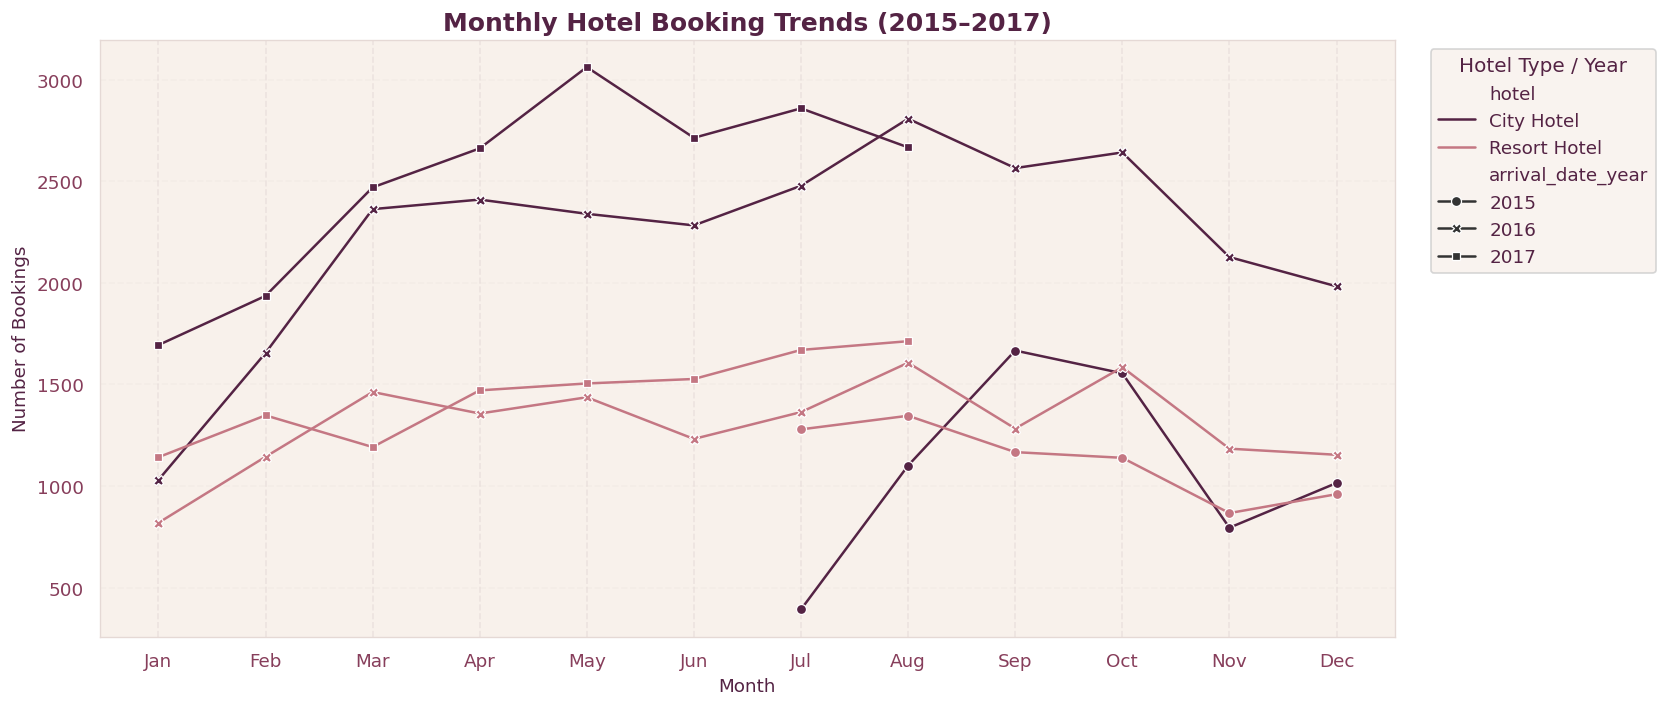

In [ ]:

monthly_bookings = (
    df.groupby(["arrival_date_year", "arrival_month_num", "hotel"])
      .size()
      .reset_index(name="booking_count")
)

month_labels = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_bookings,
    x="arrival_month_num",
    y="booking_count",
    hue="hotel",
    style="arrival_date_year",
    markers=True,
    dashes=False,
    palette=hotel_palette
)

plt.title("Monthly Hotel Booking Trends (2015–2017)",
          fontsize=15, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Bookings")
plt.xticks(range(1, 13), month_labels)
plt.legend(title="Hotel Type / Year", bbox_to_anchor=(1.02, 1))
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()


**Findings**
- Monthly booking volumes vary across the dataset, indicating seasonal changes in hotel demand.



- City Hotels generally record higher booking volumes than Resort Hotels.



- Booking patterns differ across months and years.


- The dataset covers July–December 2015 and January–August 2017. Therefore, 2015 and 2017 are incomplete calendar years, while 2016 is the only complete calendar year.

##**2. Donut chart**
*Booking Distribution by Hotel Type*

Objective: To compare the total booking distribution between City Hotels and Resort Hotels.


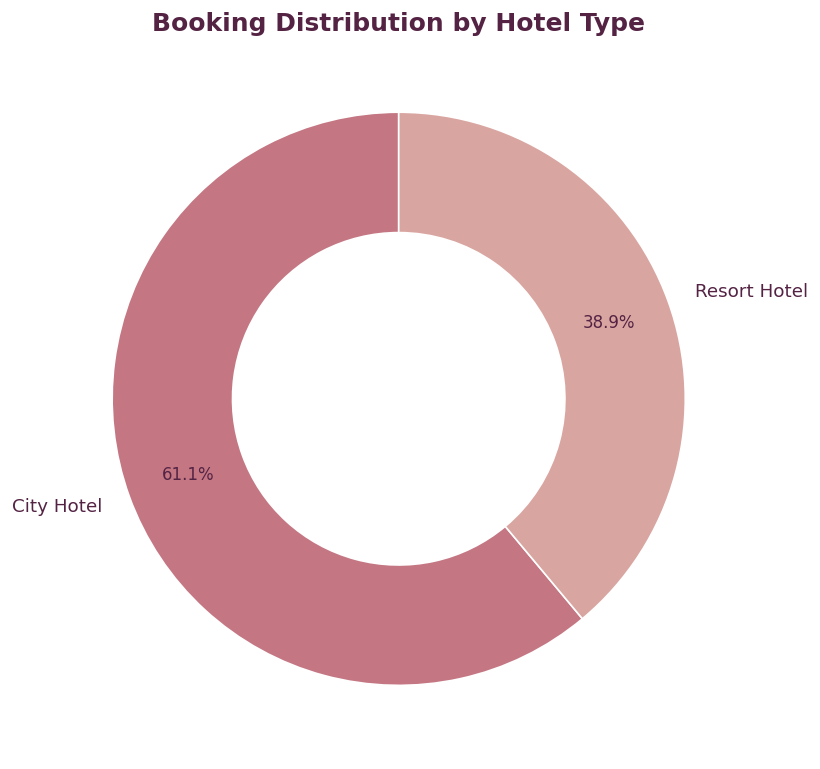

,Booking Count
hotel,
City Hotel,53274
Resort Hotel,33955


In [ ]:

hotel_counts = df["hotel"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    hotel_counts,
    labels=hotel_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=[DUSTY_ROSE, ROSE_GOLD],
    wedgeprops={"width": 0.42, "edgecolor": "white"},
    pctdistance=0.78
)

plt.title("Booking Distribution by Hotel Type",
          fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

display(hotel_counts.to_frame("Booking Count"))


**Findings**
- City Hotels account for 53,274 bookings, representing approximately 61.1% of total bookings.



- Resort Hotels account for 33,955 bookings, representing approximately 38.9% of total bookings.



- City Hotels contribute a larger share of total bookings than Resort Hotels.



- This indicates a higher booking volume for City Hotels in the dataset.

##**3. Lollipop chart**
*Cancellation Rate by Hotel Type*

Objective: To compare booking cancellation rates between City Hotels and Resort Hotels.

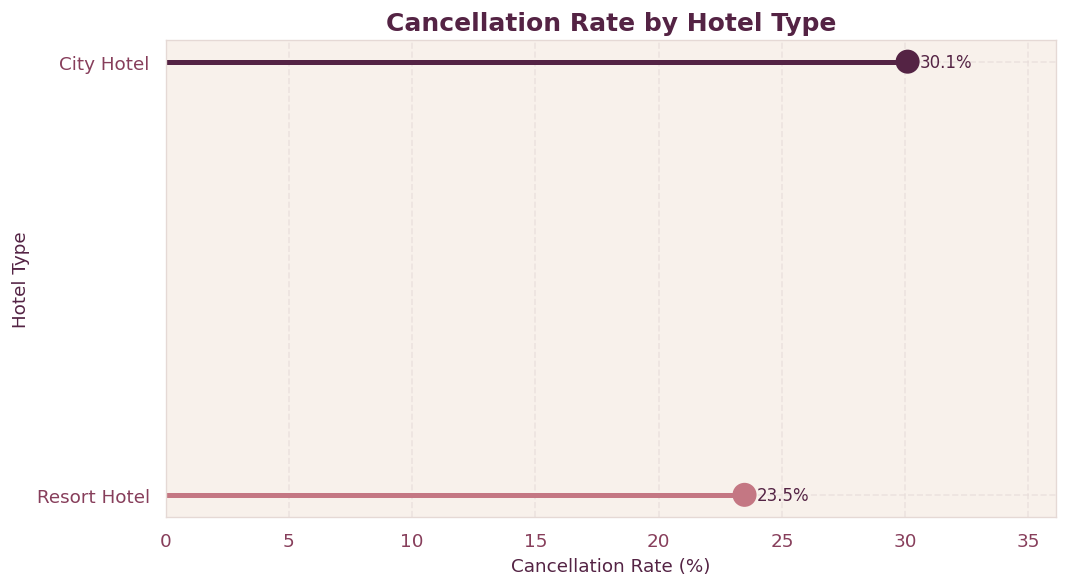

,Cancellation Rate (%)
hotel,
Resort Hotel,23.484023
City Hotel,30.099110


In [ ]:

cancellation_hotel = (
    df.groupby("hotel")["is_canceled"]
      .mean()
      .mul(100)
      .sort_values()
)

plt.figure(figsize=(9, 5))
colors = [ hotel_palette[hotel]
    for hotel in cancellation_hotel.index]
plt.hlines(
    y=cancellation_hotel.index,
    xmin=0,
    xmax=cancellation_hotel.values,
    color=colors,
    linewidth=3
)

plt.scatter(
    cancellation_hotel.values,
    cancellation_hotel.index,
    color=colors,
    s=180,
    zorder=3
)

for hotel, rate in cancellation_hotel.items():
    plt.text(rate + 0.5, hotel, f"{rate:.1f}%", va="center")

plt.title("Cancellation Rate by Hotel Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Hotel Type")
plt.xlim(0, max(cancellation_hotel.values) * 1.2)
plt.tight_layout()
plt.show()

display(cancellation_hotel.to_frame("Cancellation Rate (%)"))


**Findings**
- City Hotels have a cancellation rate of approximately 30.10%.



- Resort Hotels have a cancellation rate of approximately 23.48%.



- City Hotels experience a higher cancellation rate than Resort Hotels.



- The cancellation rate difference between the two hotel types is approximately 6.62 percentage points.

##**4. Horizontal bar chart**
*Cancellation Rate by Market Segment*

Objective: To identify market segments with higher booking cancellation rates.

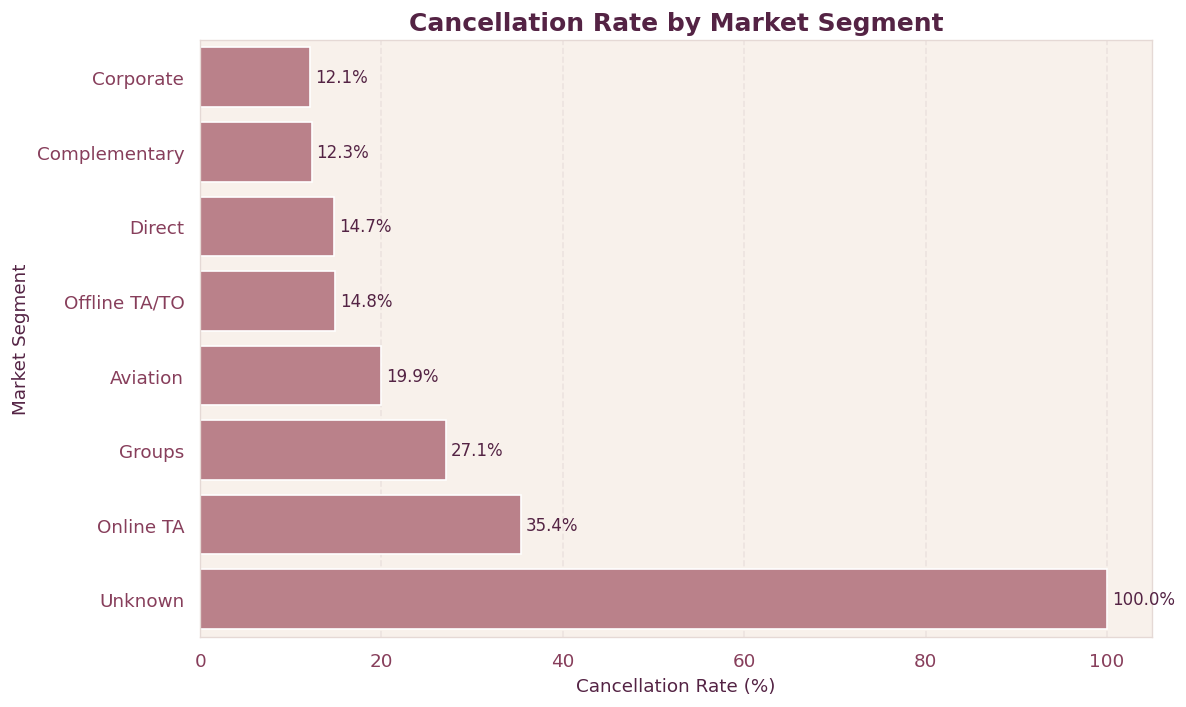

,market_segment,cancellation_rate
0,Corporate,12.119048
1,Complementary,12.283237
2,Direct,14.745331
3,Offline TA/TO,14.846626
4,Aviation,19.911504
5,Groups,27.067669
6,Online TA,35.384944
7,Unknown,100.000000


In [ ]:

segment_cancellation = (
    df.groupby("market_segment")["is_canceled"]
      .mean()
      .mul(100)
      .sort_values()
      .reset_index(name="cancellation_rate")
)

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=segment_cancellation,
    x="cancellation_rate",
    y="market_segment",
    color=DUSTY_ROSE
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.title("Cancellation Rate by Market Segment",
          fontsize=15, fontweight="bold")
plt.xlabel("Cancellation Rate (%)")
plt.ylabel("Market Segment")
plt.tight_layout()
plt.show()

display(segment_cancellation)


**Findings**
- Online TA records the highest cancellation rate among the major market segments, at approximately 35.38%.



- Groups have a cancellation rate of approximately 27.07%.



- Corporate records the lowest cancellation rate among the major segments, at approximately 12.12%.



-  The Unknown category shows a 100% cancellation rate, but it contains only 2 bookings. Therefore, this rate is not representative of the overall booking pattern.


- Cancellation behaviour varies across different market segments.

##**5. Treemap**
*Bookings by Distribution Channel*

Objective: Understand the contribution of different distribution channels to total bookings.

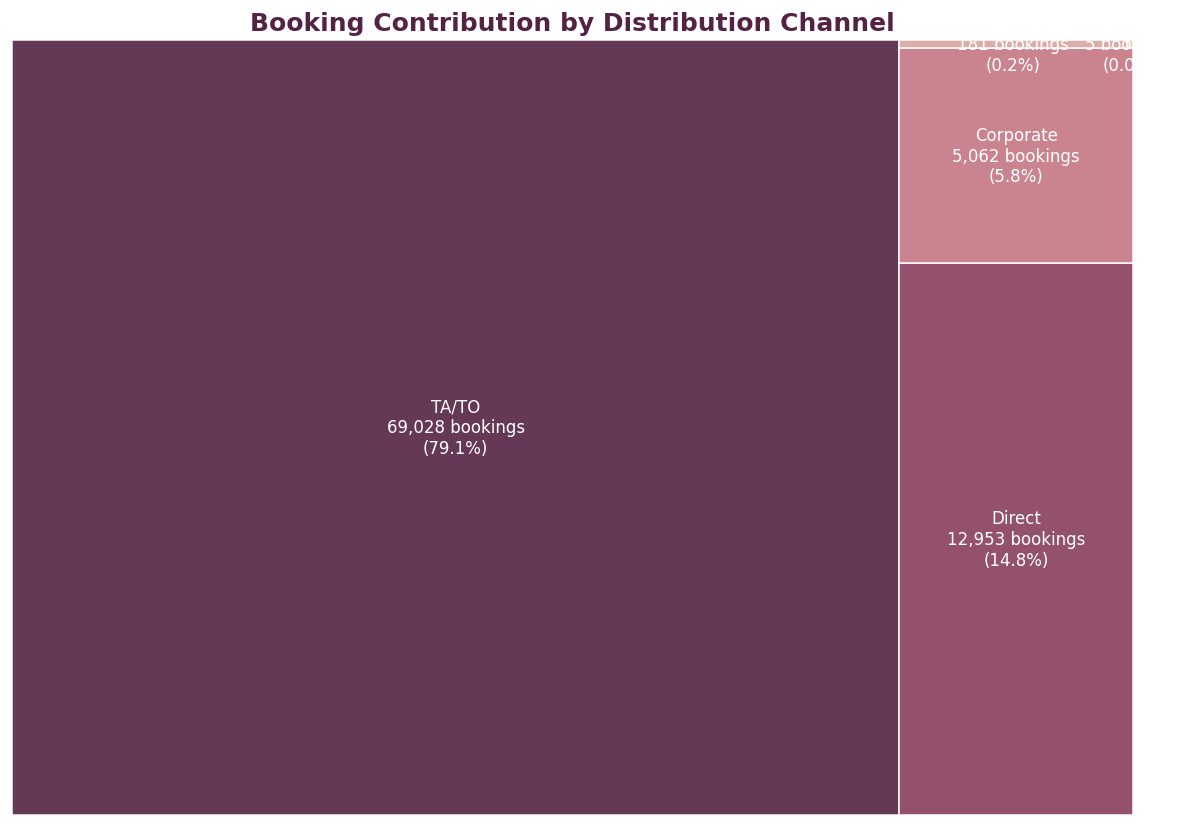

,Booking Count
distribution_channel,
TA/TO,69028
Direct,12953
Corporate,5062
GDS,181
Unknown,5


In [ ]:

# Install squarify once if it is not already installed:
# %pip install squarify
%pip install squarify
import squarify

channel_counts = df["distribution_channel"].value_counts()

plt.figure(figsize=(10, 7))

total_bookings = channel_counts.sum()

label =  [ (
        f"{channel}\n{count:,} bookings\n({count / total_bookings:.1%})"
        if count / total_bookings >= 0.01
        else ""
    )
    for channel, count in channel_counts.items()
]

squarify.plot(
    sizes=channel_counts.values,
    label=[
        f"{channel}\n{count:,} bookings\n({count / channel_counts.sum():.1%})"
        for channel, count in channel_counts.items()
    ],
    color=[BURGUNDY,PLUM,DUSTY_ROSE,ROSE_GOLD,CHAMPAGNE][:len(channel_counts)],
    alpha=0.9,
    text_kwargs={"fontsize": 10, "color": "white"}
)

plt.title("Booking Contribution by Distribution Channel",
          fontsize=15, fontweight="bold")
plt.axis("off")
plt.tight_layout()
plt.show()

display(channel_counts.to_frame("Booking Count"))


**Findings**

- TA/TO contributes the highest number of bookings, with 69,028 bookings (approximately 79.1%).



- Direct contributes 12,953 bookings (approximately 14.8%).



- Corporate contributes 5,062 bookings (approximately 5.8%).



- GDS and Unknown contribute very small proportions of total bookings.



- TA/TO is the dominant distribution channel in the dataset.

##**6. Histogram**
*ADR Distribution*

Objective: Understand the distribution of Average Daily Rate (ADR).


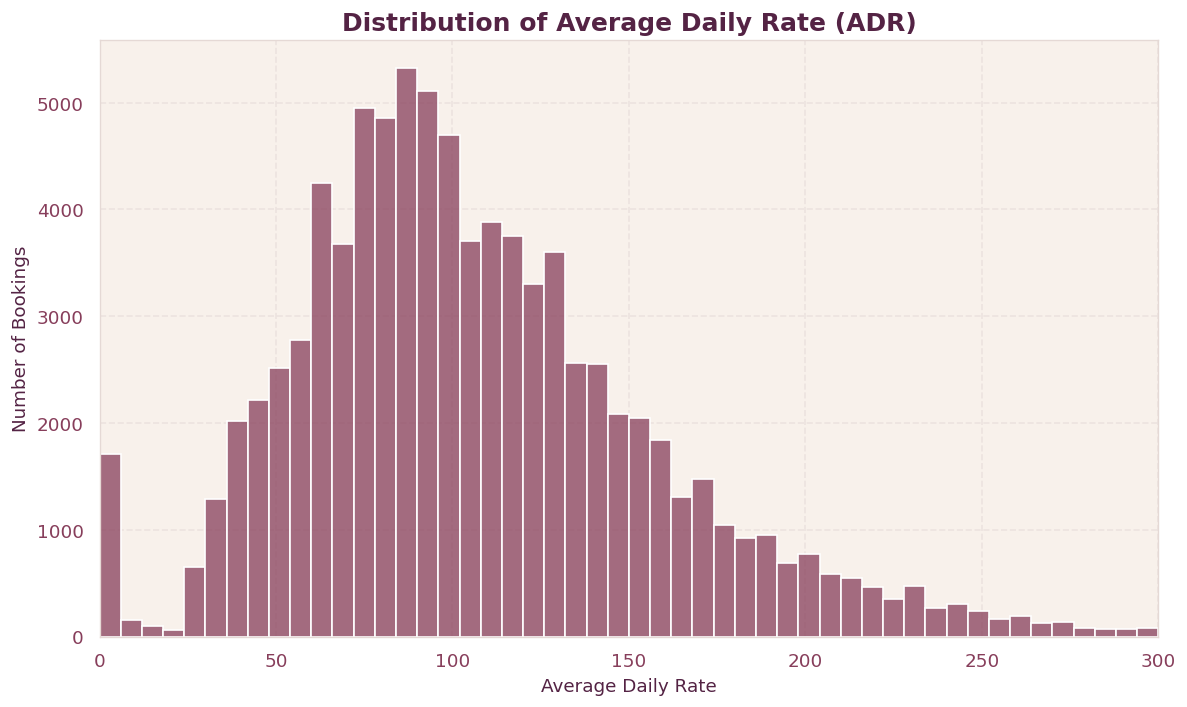

,adr
count,87229.000000
mean,106.519325
std,54.890211
min,0.000000
25%,72.250000
50%,98.200000
75%,134.100000
max,5400.000000


In [ ]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="adr",
    bins=50,
    binrange=(0, 300),
    color=PLUM,
    edgecolor="white"
)

plt.title("Distribution of Average Daily Rate (ADR)",
          fontsize=15, fontweight="bold")

plt.xlabel("Average Daily Rate")
plt.ylabel("Number of Bookings")

plt.xlim(0, 300)

plt.tight_layout()
plt.show()

display(df["adr"].describe())

**Findings**
- The average ADR is approximately 106.52, while the median ADR is 98.20.



- The middle 50% of ADR values fall between 72.25 and 134.10.

- It focuses on ADR values between 0 and 300 to show the main distribution clearly. Values outside this range are excluded from the visualization only and remain in the dataset.

- The mean being higher than the median indicates a positively skewed distribution.



- The maximum ADR value is 5,400, indicating the presence of an unusually high value.



- Most bookings are concentrated within a much lower ADR range than this maximum value.

##**7. Box plot**
*ADR Comparison by Hotel Type*

Objective: Compare room-rate distributions between City Hotels and Resort Hotels.

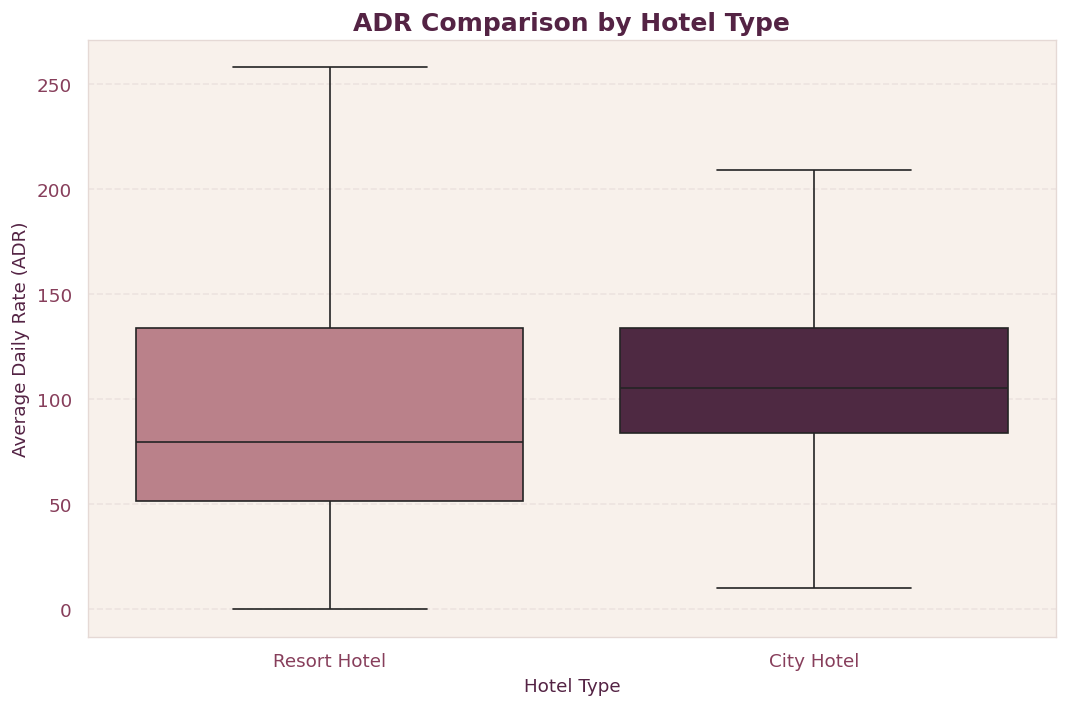

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City Hotel,53274.0,111.271969,47.801588,0.0,84.15,105.3,134.1,5400.0
Resort Hotel,33955.0,99.062622,63.750336,0.0,51.50,79.5,134.1,508.0


In [ ]:

plt.figure(figsize=(9, 6))

sns.boxplot(
    data=df,
    x="hotel",
    y="adr",
    hue="hotel",
    palette=hotel_palette,
    showfliers=False,
    legend=False
)

plt.title("ADR Comparison by Hotel Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.tight_layout()
plt.show()

display(df.groupby("hotel")["adr"].describe())


**Findings**
- City Hotels have a median ADR of 105.30.



- Resort Hotels have a median ADR of 79.50.



- City Hotels generally have higher room rates based on the median ADR.



- Resort Hotels show greater variation in ADR values, as indicated by their higher standard deviation.



- The box plot hides individual outlier points for better readability, but the descriptive statistics retain the full range of values.

##**8. Violin plot**
*Length of Stay Distribution*

Objective: Compare the distribution of guest stay durations between hotel types.

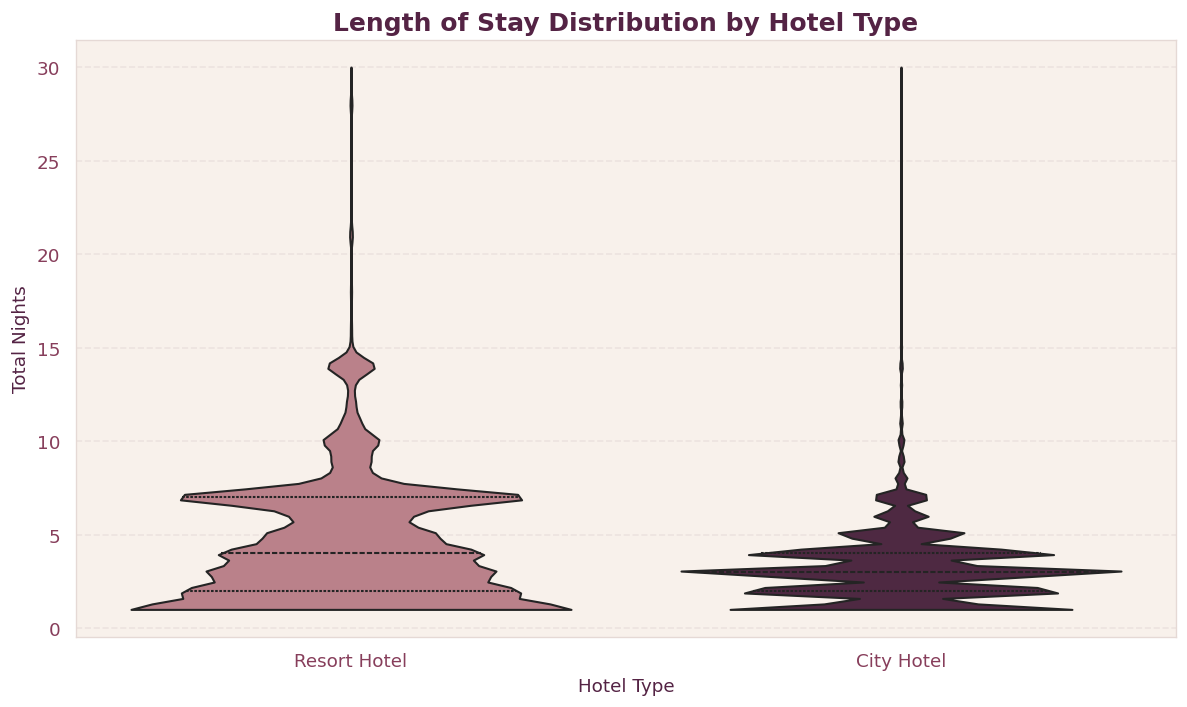

,count,mean,std,min,25%,50%,75%,max
hotel,,,,,,,,
City Hotel,53040.0,3.153639,2.018023,1.0,2.0,3.0,4.0,30.0
Resort Hotel,33578.0,4.418875,3.303743,1.0,2.0,4.0,7.0,30.0


In [ ]:

stay_data = df[df["total_nights"].between(1, 30)].copy()

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=stay_data,
    x="hotel",
    y="total_nights",
    hue="hotel",
    palette=hotel_palette,
    inner="quart",
    cut=0,
    legend=False
)

plt.title("Length of Stay Distribution by Hotel Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Hotel Type")
plt.ylabel("Total Nights")
plt.tight_layout()
plt.show()

display(stay_data.groupby("hotel")["total_nights"].describe())


**Findings**
- Among bookings with stays between 1 and 30 nights, City Hotel guests have an average stay of approximately 3.15 nights.



- Among bookings with stays between 1 and 30 nights, Resort Hotel guests have an average stay of approximately 4.42 nights.



- The median stay is 3 nights for City Hotels and 4 nights for Resort Hotels.



- Resort Hotel guests generally stay longer than City Hotel guests.



- The visualization includes stays between 1 and 30 nights.

##**9. Choropleth map**
*Top 10 Countries by Booking Count*

Objective: Examine the geographical distribution of hotel bookings by guest country.


In [ ]:

import plotly.express as px

country_counts = (
    df[df["country"].notna() & (df["country"] != "Unknown")]
    .groupby("country")
    .size()
    .reset_index(name="booking_count")
)

# Select the top 10 countries
top_10_countries = country_counts.sort_values(
    "booking_count", ascending=False
).head(10)

fig = px.choropleth(
    top_10_countries,
    locations="country",
    color="booking_count",
    hover_name="country",
    hover_data={"booking_count": True},
    locationmode="ISO-3",
    color_continuous_scale=[
        "#F8F1EB","#E8CBAE","#D9A5A0","#C47783","#873E5B","#542344"
    ],
    title="Top 10 Countries by Hotel Booking Count"
)

fig.update_layout(
    title_x=0.5,
    title_font_size=18,
    height=600
)

fig.show()

display(top_10_countries)


,country,booking_count
135,PRT,27355
59,GBR,10423
56,FRA,8823
51,ESP,7244
43,DEU,5385
81,ITA,3061
76,IRL,3015
15,BEL,2081
25,BRA,1993
123,NLD,1910


**Findings**
- Portugal (PRT) contributes the highest number of bookings, with 27,355.



- The United Kingdom (GBR) contributes 10,423 bookings.



- France (FRA) contributes 8,823 bookings.



- Spain (ESP) contributes 7,244 bookings.



- Germany (DEU) contributes 5,385 bookings.



- Portugal contributes substantially more bookings than the other countries in the top 10.

-  The country ranking includes only bookings with known country information; records marked as Unknown are excluded.

##**10. Scatter plot**
*Lead Time vs ADR*

Objective: Examine the relationship between the number of days between booking and arrival and the Average Daily Rate.

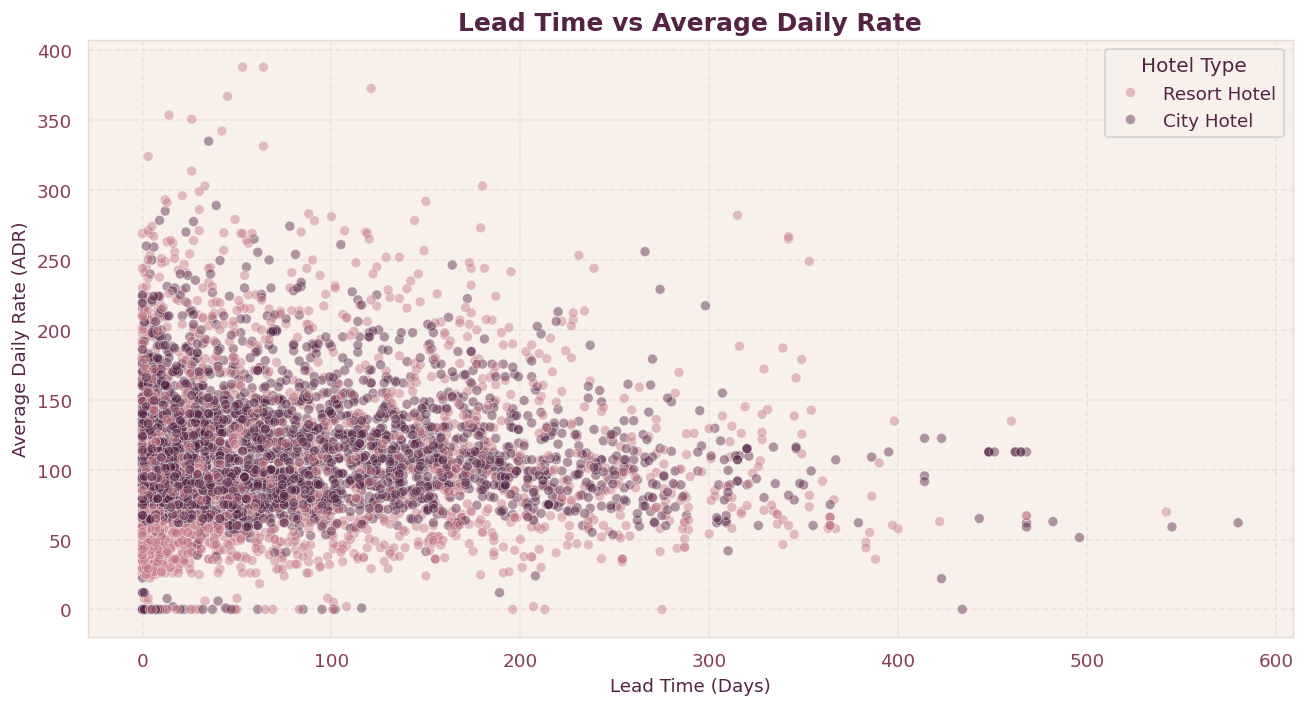

In [ ]:

# Take a sample only for clearer visualization.
# The original DataFrame remains unchanged.
scatter_data = df.sample(
    n=min(5000, len(df)),
    random_state=42
)

plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=scatter_data,
    x="lead_time",
    y="adr",
    hue="hotel",
    palette=hotel_palette,
    alpha=0.45,
    s=35
)

plt.title("Lead Time vs Average Daily Rate",
          fontsize=15, fontweight="bold")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Average Daily Rate (ADR)")
plt.legend(title="Hotel Type")
plt.tight_layout()
plt.show()


**Findings**
- The scatter plot examines the relationship between lead time and Average Daily Rate.


- The correlation between lead time and ADR is approximately 0.02, indicating almost no linear association between the two variables.


- ADR values vary considerably across different lead-time values.



-  The scatter plot does not show a clear linear relationship between lead time and ADR.



-  Both City Hotels and Resort Hotels show considerable variation in room rates across booking periods.

- The scatter plot uses a random sample of 5,000 records for visualization clarity; the original dataset remains unchanged.


##**11. Stacked bar chart**
*Customer Type Distribution by Hotel*

Objective: Compare the proportion of different customer types within City Hotels and Resort Hotels.


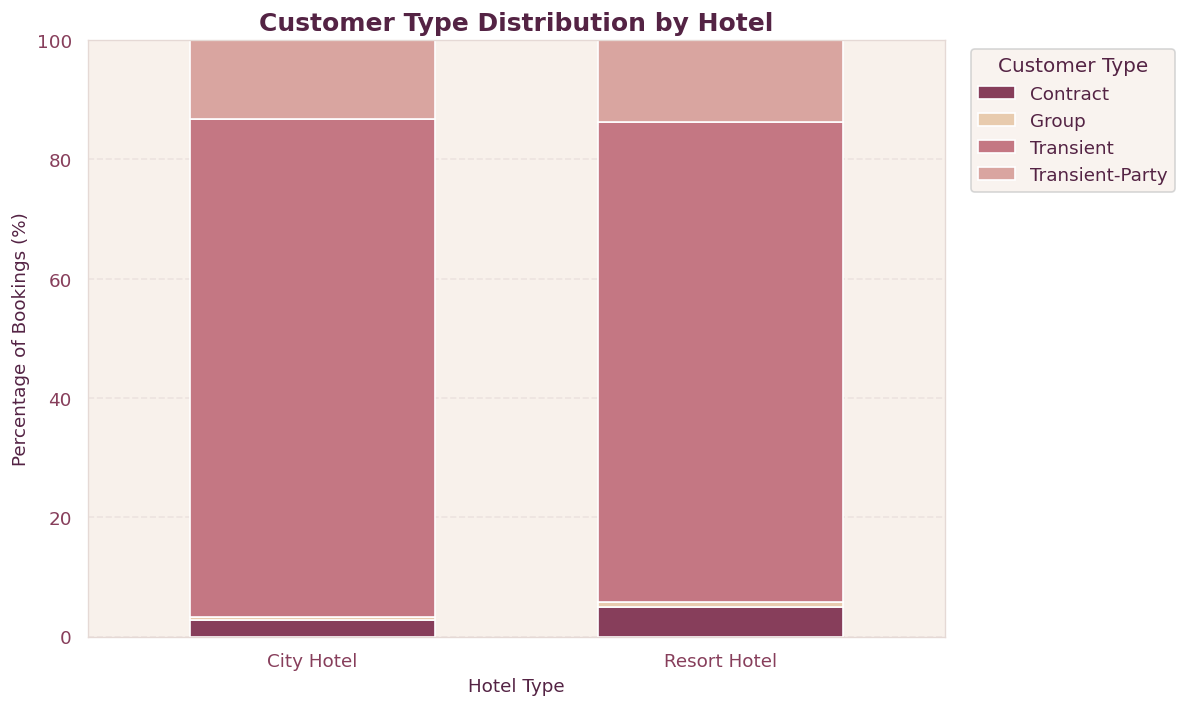

customer_type,Contract,Group,Transient,Transient-Party
hotel,,,,
City Hotel,2.75,0.5,83.57,13.17
Resort Hotel,4.91,0.8,80.52,13.77


In [ ]:

customer_pivot = pd.crosstab(
    df["hotel"],
    df["customer_type"],
    normalize="index"
) * 100

customer_pivot = customer_pivot.reindex(
    ["City Hotel", "Resort Hotel"]
)

customer_pivot.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=[PLUM,CHAMPAGNE,DUSTY_ROSE,ROSE_GOLD],
    width=0.6
)

plt.title("Customer Type Distribution by Hotel",
          fontsize=15, fontweight="bold")
plt.xlabel("Hotel Type")
plt.ylabel("Percentage of Bookings (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Customer Type", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

display(customer_pivot.round(2))


**Findings**
-  Transient customers represent the largest customer category in both hotel types.



- Transient customers account for 83.57% of City Hotel bookings.



- Transient customers account for 80.52% of Resort Hotel bookings.



- Transient-Party customers contribute 13.17% of City Hotel bookings and 13.77% of Resort Hotel bookings.



- Contract and Group customers represent smaller proportions of bookings in both hotel types.

##**12. Heatmap**
*Correlation Heatmap*

Objective: Examine the strength and direction of relationships between selected numerical variables.

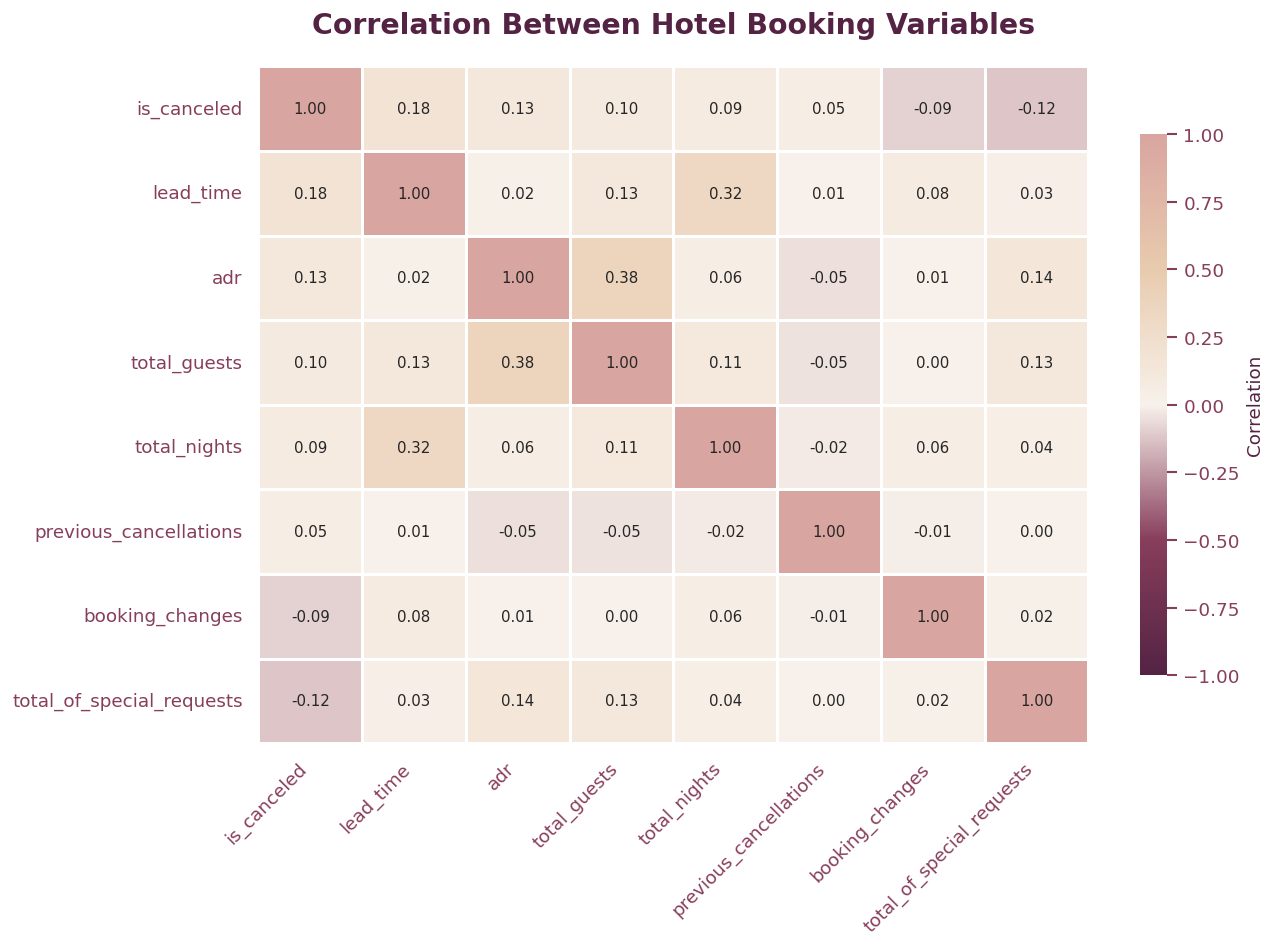

In [ ]:

from matplotlib.colors import LinearSegmentedColormap

burgundy_rose = LinearSegmentedColormap.from_list(
    "burgundy_rose",
    [
        (0.0, BURGUNDY),
        (0.25, PLUM),
        (0.5, IVORY),
        (0.75, CHAMPAGNE),
        (1.0, ROSE_GOLD)
    ]
)

# Select numerical columns for correlation analysis
correlation_columns = [
    "is_canceled",
    "lead_time",
    "adr",
    "total_guests",
    "total_nights",
    "previous_cancellations",
    "booking_changes",
    "total_of_special_requests"
]

# Calculate correlation matrix
correlation_matrix = df[correlation_columns].corr()

# Plot heatmap
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap=burgundy_rose,
    center=0,
    vmin=-1,
    vmax=1,
    fmt=".2f",
    linewidths=0.8,
    linecolor="white",
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.8, "label": "Correlation"}
)

plt.title(
    "Correlation Between Hotel Booking Variables",
    fontsize=17,
    fontweight="bold",
    color=BURGUNDY,
    pad=20
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


**Findings**
- Lead time has the strongest positive correlation with booking cancellations among the selected variables, with a correlation coefficient of approximately 0.18.



- ADR has a weak positive correlation with cancellations, at approximately 0.13.



- Total guests have a weak positive correlation with cancellations, at approximately 0.10.



- Total nights have a weak positive correlation with cancellations, at approximately 0.09.



- Total special requests show a negative correlation with cancellations, at approximately -0.12.



- Booking changes also show a negative correlation with cancellations, at approximately -0.09.



- These results indicate associations between variables and cancellations, not cause-and-effect relationships.

####**Overall Exploratory Data Analysis Findings**

- City Hotels contribute a larger share of total bookings than Resort Hotels.
- City Hotels have a higher cancellation rate compared with Resort Hotels.
- Online TA records the highest cancellation rate among the major market segments.
- TA/TO is the dominant distribution channel for hotel bookings.
- Portugal contributes the highest number of bookings among the countries represented in the dataset.
- City Hotels have a higher median ADR, while Resort Hotel guests generally have longer stays.
- Transient customers represent the largest customer category in both hotel types.
- Lead time shows the strongest positive correlation with booking cancellations among the selected numerical variables.
- The analysis highlights differences in booking patterns, cancellation behaviour, pricing, and customer preferences across hotel types and customer segments.
- City and Resort Hotels show different booking patterns and cancellation behaviour across the analyzed period.
- The relationship between lead time and cancellation is positive but weak, so lead time alone does not explain cancellations

In [ ]:
# @title
from IPython.display import HTML, display

display(HTML("""
<div style="
background-color: #D87093;
padding: 12px;
border-radius: 8px;
text-align: center;
">
<h2 style="color: 	#28282B; margin: 0;">
Visualization
</h2>
</div>
"""))